In [ ]:
# load_data.py  (second file)
import os
from pathlib import Path
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

WORK_DIR = Path("animal")   # must match the first file
IMG_SIZE = (64, 64)
SEED     = 42
BATCH    = 64

train_ds = tf.keras.utils.image_dataset_from_directory(
    str(WORK_DIR / "train"), image_size=IMG_SIZE, batch_size=BATCH,
    seed=SEED, shuffle=True)
val_ds = tf.keras.utils.image_dataset_from_directory(
    str(WORK_DIR / "val"), image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    str(WORK_DIR / "test"), image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

print("Classes:", train_ds.class_names)

# Scale pixels to 0-1 for the custom model A
normalize = tf.keras.layers.Rescaling(1.0 / 255)
train_ds_n = train_ds.map(lambda x, y: (normalize(x), y), num_parallel_calls=tf.data.AUTOTUNE)
val_ds_n   = val_ds.map(lambda x, y: (normalize(x), y),   num_parallel_calls=tf.data.AUTOTUNE)
test_ds_n  = test_ds.map(lambda x, y: (normalize(x), y),  num_parallel_calls=tf.data.AUTOTUNE)

Found 2100 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Classes: ['cats', 'dogs', 'snakes']


In [9]:
from tensorflow.keras import layers, models
import time

tf.keras.utils.set_random_seed(SEED)        # reproducible weight initialisation
NUM_CLASSES = len(train_ds.class_names)
AUTOTUNE = tf.data.AUTOTUNE

# Keep decoded images in memory and prepare the next batch while the GPU trains (faster epochs).
# Training data: cache single images, then re-shuffle every epoch and re-batch.
train_ds_n = (train_ds_n.unbatch().cache()
              .shuffle(2000, seed=SEED, reshuffle_each_iteration=True)
              .batch(BATCH).prefetch(AUTOTUNE))
val_ds_n   = val_ds_n.cache().prefetch(AUTOTUNE)
test_ds_n  = test_ds_n.cache().prefetch(AUTOTUNE)

def build_model_a(input_shape=(64, 64, 3), num_classes=NUM_CLASSES):
    inputs = layers.Input(shape=input_shape)
    x = inputs
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, kernel_size=3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return models.Model(inputs, outputs, name="Model_A_StandardCNN")

model_a = build_model_a()

In [10]:
def conv_params(k, c_in, c_out):  return k * k * c_in * c_out + c_out
def dense_params(n_in, n_out):     return n_in * n_out + n_out
def conv_macs(h, w, k, c_in, c_out): return h * w * k * k * c_in * c_out   # 'same' padding, stride 1

rows = []   # (layer, params, MACs)
c_in, size = 3, 64
for f in [32, 64, 128, 256]:
    rows.append((f"Conv2D 3x3, {f} ({size}x{size})", conv_params(3, c_in, f), conv_macs(size, size, 3, c_in, f)))
    c_in, size = f, size // 2
rows.append(("Dense 128", dense_params(256, 128), 256 * 128))
rows.append((f"Dense {NUM_CLASSES}", dense_params(128, NUM_CLASSES), 128 * NUM_CLASSES))

print(f"{'Layer':<30}{'Params':>12}{'MACs':>16}")
for name, p, m in rows:
    print(f"{name:<30}{p:>12,}{m:>16,}")
total_p = sum(r[1] for r in rows); total_m = sum(r[2] for r in rows)
print(f"{'TOTAL':<30}{total_p:>12,}{total_m:>16,}")
print("Keras count:", f"{model_a.count_params():,}", "| match:", total_p == model_a.count_params())

Layer                               Params            MACs
Conv2D 3x3, 32 (64x64)                 896       3,538,944
Conv2D 3x3, 64 (32x32)              18,496      18,874,368
Conv2D 3x3, 128 (16x16)             73,856      18,874,368
Conv2D 3x3, 256 (8x8)              295,168      18,874,368
Dense 128                           32,896          32,768
Dense 3                                387             384
TOTAL                              421,699      60,195,200
Keras count: 421,699 | match: True


In [11]:
class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._t = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self._t)

EPOCHS = 20
model_a.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])

timer_a = EpochTimer()
history_a = model_a.fit(train_ds_n, validation_data=val_ds_n, epochs=EPOCHS, callbacks=[timer_a])

# first epoch includes one-off setup (graph building, caching), so report the mean of the rest
print(f"Average time per epoch (epochs 2-{EPOCHS}): {np.mean(timer_a.times[1:]):.2f} s")

Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.4043 - loss: 1.0539 - val_accuracy: 0.5444 - val_loss: 0.8989
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.5171 - loss: 0.9381 - val_accuracy: 0.5689 - val_loss: 0.8857
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.5657 - loss: 0.8613 - val_accuracy: 0.5622 - val_loss: 0.8429
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 121ms/step - accuracy: 0.5786 - loss: 0.8313 - val_accuracy: 0.6400 - val_loss: 0.7820
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 118ms/step - accuracy: 0.5971 - loss: 0.7990 - val_accuracy: 0.6222 - val_loss: 0.7518
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 117ms/step - accuracy: 0.6310 - loss: 0.7639 - val_accuracy: 0.6400 - val_loss: 0.7625
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 119ms/step - accuracy: 0.6276 - loss: 0.7616 - val_accuracy: 0.6911 - val_loss: 0.7065
Epoch 8/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 116ms/step - accuracy: 0.6467 - loss: 0.7471 - val_accuracy: 0.677

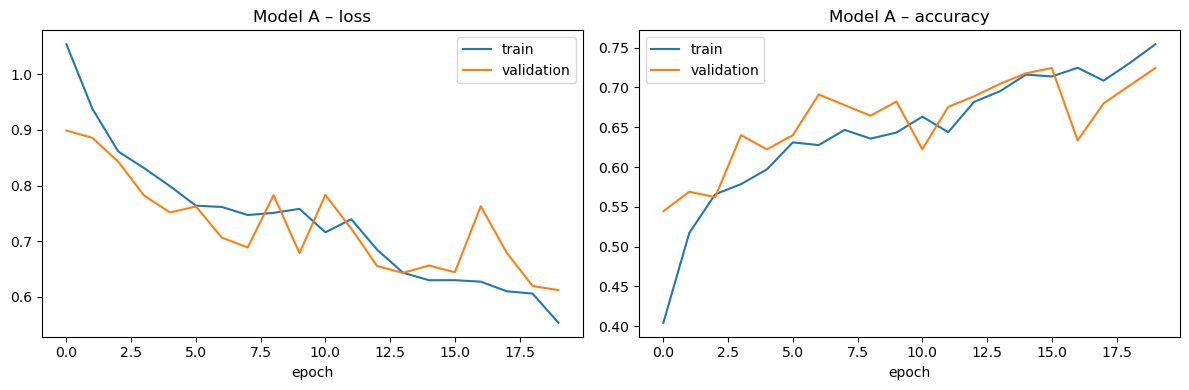

In [12]:
def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history["loss"], label="train");     ax[0].plot(history.history["val_loss"], label="validation")
    ax[0].set_title(f"{title} – loss");     ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="validation")
    ax[1].set_title(f"{title} – accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout()
    plt.savefig(WORK_DIR / f"{title.replace(' ', '_')}_curves.png", dpi=150)
    plt.show()

plot_history(history_a, "Model A")

Model A test accuracy: 0.7267

              precision    recall  f1-score   support

        cats     0.6066    0.8533    0.7091       150
        dogs     0.7889    0.4733    0.5917       150
      snakes     0.8591    0.8533    0.8562       150

    accuracy                         0.7267       450
   macro avg     0.7515    0.7267    0.7190       450
weighted avg     0.7515    0.7267    0.7190       450



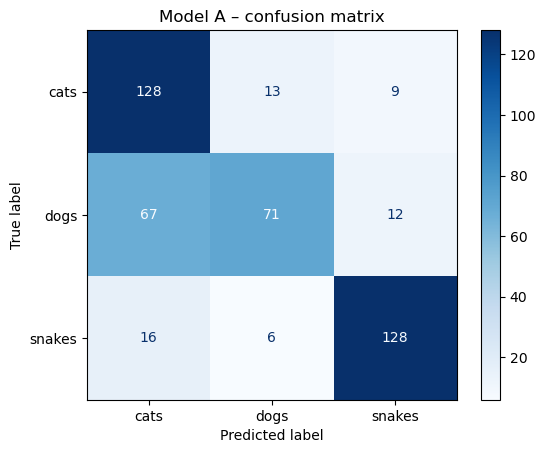

In [13]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

def evaluate(model, ds, title):
    y_true = np.concatenate([y.numpy() for _, y in ds])
    y_pred = np.argmax(model.predict(ds, verbose=0), axis=1)
    names = train_ds.class_names
    acc = np.mean(y_true == y_pred)
    print(f"{title} test accuracy: {acc:.4f}\n")
    print(classification_report(y_true, y_pred, target_names=names, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=names).plot(cmap="Blues", values_format="d")
    plt.title(f"{title} – confusion matrix")
    plt.savefig(WORK_DIR / f"{title.replace(' ', '_')}_confusion.png", dpi=150, bbox_inches="tight")
    plt.show()
    return acc

test_acc_a = evaluate(model_a, test_ds_n, "Model A")

In [14]:
def deploy_size_kb(model, build_fn, path):
    """Save an uncompiled copy (weights only, no optimizer state) and return its size in KB."""
    clean = build_fn()
    clean.set_weights(model.get_weights())
    clean.save(path)
    return os.path.getsize(path) / 1024

model_a.save(WORK_DIR / "model_a_full.keras")   # full model incl. optimizer, to resume training later
size_a_kb = deploy_size_kb(model_a, build_model_a, WORK_DIR / "model_a.keras")

print(f"Model A: {model_a.count_params():,} params")
print(f"  weights file on disk : {size_a_kb:.1f} KB")
print(f"  theoretical float32  : {model_a.count_params() * 4 / 1024:.1f} KB  (4 bytes per weight)")
print(f"  if quantised to int8 : {model_a.count_params() / 1024:.1f} KB  (1 byte per weight)")
print(f"  time per epoch       : {np.mean(timer_a.times[1:]):.2f} s")
print(f"  test accuracy        : {test_acc_a:.4f}")

NameError: name 'os' is not defined